In [39]:
%matplotlib widget
import importlib
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd
import io

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\COMSOL\SPR')
import Treat_SPR_func as Treat_SPR_func
importlib.reload(Treat_SPR_func)
from Treat_SPR_func import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolation_func_VF import *
import AR_interpolation_func_VF
importlib.reload(AR_interpolation_func_VF)
from AR_interpolation_func_VF import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\AR_estimation\New_code')
from AR_interpolations_plotting_VF import *
import AR_interpolations_plotting_VF
importlib.reload(AR_interpolations_plotting_VF)
from AR_interpolations_plotting_VF import *


fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

In [40]:
path_simu = r'H:\commun\Utilisateur FNO\Nathan\COMSOL\AuND\Optical detection\Optical - acoustic coupling\Sapphire'

simu_shape = 'cylinder'
sample_name = 'Silice thick - e 40 nm'

dir_root = '\\'.join((path_simu, sample_name, simu_shape))
dir_root = path_simu

Fname_list = ['test SPR']
#fname_raw = 'Sapphire - raw simu results'
Spectra_data = get_raw_size_sweep_data_Nathan(dir_root, Fname_list)
#Spectra_data = get_raw_size_sweep_data_Aurelien(dir_root, fname_raw)

fit_Lorentz_all_data(Spectra_data, w_guess=0.1)

dir_to_save = dir_root + '\Treated_SPR'


fname = 'Treated_simulations'
#save_treated_simulation_data(Spectra_data, dir_to_save, fname)

Total size of raw data : 8
----------- Find spectra size -----------
failed !
Failed to converge : ND_D_97.0_h_22.7
-------------------


<>:16: SyntaxWarning: invalid escape sequence '\T'
<>:16: SyntaxWarning: invalid escape sequence '\T'
C:\Users\nberr\AppData\Local\Temp\ipykernel_14092\2620105448.py:16: SyntaxWarning: invalid escape sequence '\T'
  dir_to_save = dir_root + '\Treated_SPR'


C:\Users\nberr\AppData\Local\Temp\ipykernel_14092\1350544824.py:12: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize = (9,4))


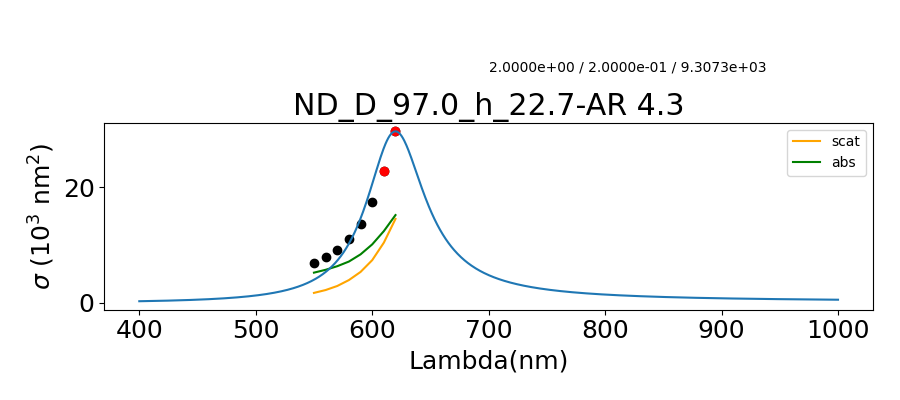

In [41]:
Lambda = np.linspace(400, 1000, 1000)
E = 1240/Lambda

if 1 :
        
    for key in Spectra_data :
        
        spectra = Spectra_data[key]

        if spectra['res_fit']['converged'] == 1 or spectra['res_fit']['converged'] == 0 :
                
            fig, ax = plt.subplots(figsize = (9,4))

            ax.scatter(spectra['Lambda'], spectra['Sigma_ext']*1e-3, color='black')
            ax.plot(spectra['Lambda'], spectra['Sigma_scat']*1e-3, color='orange', label='scat')
            ax.plot(spectra['Lambda'], spectra['Sigma_abs']*1e-3, color='green', label='abs')


            ax.plot(1240/E, Lorentz_no_offset(E, *spectra['res_fit']['coeffs'])*1e-3)
            ax.set_title(key + '-' + 'AR '+ str(spectra['AR']))
            ax.scatter(spectra['Lambda'][spectra['res_fit']['idx']], spectra['Sigma_ext'][spectra['res_fit']['idx']]*1e-3, color='red')
            ax.set_xlabel('Lambda(nm)')
            ax.text(700, 40, "{:.4e} / {:.4e} / {:.4e}".format(*spectra['res_fit']['coeffs']), fontsize = 10)
            ax.set_ylabel(r'$\sigma$ ($10^3$ nm$^2$)')
            plt.legend(fontsize=10)
            plt.tight_layout()